# Практика 4 — Transfer learning
## Beans: диагностика болезней листьев фасоли по фото

**Assignment 4** · Азиз Абдулин · повтор практики курса по transfer learning на новом датасете.

**Датасет.** Beans (Makerere AI Lab, 2020; лицензия MIT): снимки листьев фасоли на смартфон с полей Уганды, три класса —
*угловатая пятнистость*, *ржавчина* и *здоровый лист*. 1 034 изображения в train, 133 в validation и 128 в test,
500×500 пикселей. Маленький датасет — как раз тот случай, где transfer learning должен помогать.

**Вопрос.** Помогает ли сеть, предобученная на ImageNet (1,3 млн обычных фото, болезней растений там нет), распознавать
болезни листьев по сравнению с сетью, обученной с нуля на 1 034 изображениях?

**План.** 1) данные · 2) CNN с нуля · 3) замороженные предобученные сети (ResNet-18, EfficientNet-B0) + линейный
классификатор · 4) сравнение · 5) сколько размеченных данных нужно каждому подходу · 6) ошибки · 7) выводы.

In [1]:
import io, json, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as Fn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from a4_metrics import accuracy, macro_f1, confusion, bootstrap_ci

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
DEV = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
DATA, FIG, RES = Path("data"), Path("figures"), Path("results")
for d in (DATA, FIG, RES): d.mkdir(exist_ok=True)
URL = "https://huggingface.co/api/datasets/AI-Lab-Makerere/beans/parquet/default/{}/0.parquet"
split = {}
for s in ("train", "validation", "test"):
    f = DATA / f"beans_{s}.parquet"
    if not f.exists(): urllib.request.urlretrieve(URL.format(s), f)
    d = pd.read_parquet(f)
    split[s] = ([Image.open(io.BytesIO(b["bytes"])).convert("RGB") for b in d.image], d.labels.to_numpy())
CLASSES = ["angular leaf spot", "bean rust", "healthy"]
print("device:", DEV, {s: (len(v[1]), np.bincount(v[1]).tolist()) for s, v in split.items()}, "image size:", split["train"][0][0].size)

device: mps {'train': (1034, [345, 348, 341]), 'validation': (133, [44, 45, 44]), 'test': (128, [43, 43, 42])} image size: (500, 500)


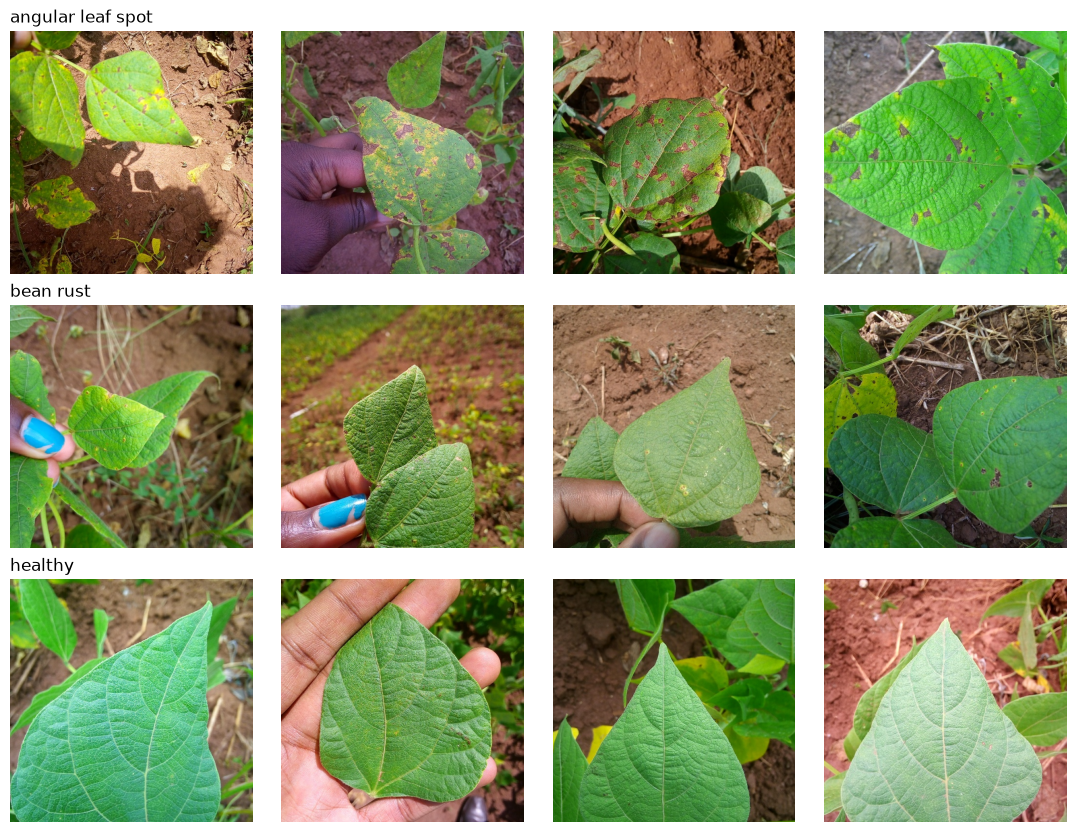

In [2]:
fig, ax = plt.subplots(3, 4, figsize=(11, 8.4))
imgs, ys = split["train"]
for r, c in enumerate(range(3)):
    idx = np.where(ys == c)[0][:4]
    for j, i in enumerate(idx):
        ax[r, j].imshow(imgs[i]); ax[r, j].axis("off")
    ax[r, 0].set_title(CLASSES[c], loc="left", fontsize=12)
plt.tight_layout(); plt.savefig(FIG / "p4_examples.png", dpi=100); plt.show()

Ржавчина — мелкие круглые оранжево-коричневые пустулы, угловатая пятнистость — бурые пятна, ограниченные жилками.
Фон, освещение и число листьев в кадре сильно различаются.

In [3]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]          # ImageNet statistics, expected by the pre-trained nets
class Leaves(Dataset):
    def __init__(self, imgs, ys, tf): self.imgs, self.ys, self.tf = imgs, ys, tf
    def __len__(self): return len(self.ys)
    def __getitem__(self, i): return self.tf(self.imgs[i]), int(self.ys[i])

def evaluate(model, loader):
    model.eval(); preds, ys = [], []
    with torch.no_grad():
        for x, y in loader:
            preds.append(model(x.to(DEV)).argmax(1).cpu()); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(preds).numpy()

## 2. CNN, обученная с нуля

Четыре свёрточных блока (32 → 64 → 128 → 256 каналов, батч-нормализация, max pooling), глобальный средний пулинг и
линейный слой — около 1,2 млн весов, все обучаются на 1 034 изображениях train. Изображения уменьшены до 128×128 и
аугментированы (случайное кадрирование, отражения, небольшие повороты, изменение цвета) против переобучения. AdamW,
шаг 1e-3 с косинусным снижением, 30 эпох; сохраняется эпоха с лучшей точностью на validation.

trained in 198 s, 1,174,947 weights, best val accuracy 0.962


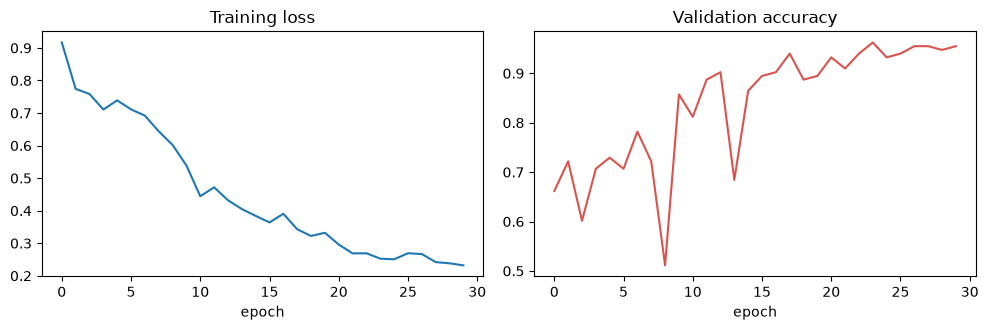

In [4]:
tf_small_train = T.Compose([T.RandomResizedCrop(128, scale=(0.5, 1.0)), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                            T.RandomRotation(15), T.ColorJitter(0.2, 0.2, 0.2), T.ToTensor(), T.Normalize(MEAN, STD)])
tf_small_eval = T.Compose([T.Resize(146), T.CenterCrop(128), T.ToTensor(), T.Normalize(MEAN, STD)])

def small_cnn():
    block = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.Conv2d(o, o, 3, padding=1),
                                       nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
    return nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256), nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                         nn.Dropout(0.3), nn.Linear(256, 3))

def train_scratch(idx, epochs=30, log=False):
    torch.manual_seed(SEED)
    imgs, ys = split["train"]
    tl = DataLoader(Leaves([imgs[i] for i in idx], ys[idx], tf_small_train), batch_size=32, shuffle=True)
    vl = DataLoader(Leaves(*split["validation"], tf_small_eval), batch_size=64)
    m = small_cnn().to(DEV)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs * len(tl))
    best, state, hist = -1, None, []
    for ep in range(epochs):
        m.train(); tot = 0
        for x, y in tl:
            x, y = x.to(DEV), y.to(DEV); loss = Fn.cross_entropy(m(x), y)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step(); tot += loss.item() * len(y)
        acc = accuracy(*evaluate(m, vl)); hist.append((tot / len(idx), acc))
        if acc > best: best, state = acc, {k: v.detach().clone() for k, v in m.state_dict().items()}
    m.load_state_dict(state)
    return m, hist

t = time.time(); cnn, hist = train_scratch(np.arange(len(split["train"][1]))); t_cnn = time.time() - t
print(f"trained in {t_cnn:.0f} s, {sum(p.numel() for p in cnn.parameters()):,} weights, best val accuracy {max(h[1] for h in hist):.3f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot([h[0] for h in hist]); ax[0].set(title="Training loss", xlabel="epoch")
ax[1].plot([h[1] for h in hist], color="#d9534f"); ax[1].set(title="Validation accuracy", xlabel="epoch")
plt.tight_layout(); plt.savefig(FIG / "p4_scratch_curves.png", dpi=110); plt.show()

## 3. Замороженные предобученные сети + линейный классификатор

Предобученная сеть используется как неизменный **извлекатель признаков**: её слой классификации убран, каждое изображение
один раз проходит через сеть (224×224, без аугментации) и превращается в вектор — 512 чисел у ResNet-18, 1 280 у
EfficientNet-B0. Обучается только линейный классификатор (один слой, то есть мультиномиальная логистическая регрессия)
на этих векторах. Ни один вес сети не меняется — это transfer learning в чистом виде.

In [5]:
tf_eval = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(), T.Normalize(MEAN, STD)])
BACKBONES = {"ResNet-18": lambda: models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1),
             "EfficientNet-B0": lambda: models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)}

def features(name):
    net = BACKBONES[name]()
    if name == "ResNet-18": net.fc = nn.Identity()
    else: net.classifier = nn.Identity()
    net = net.to(DEV).eval()
    out = {}
    with torch.no_grad():
        for s, (imgs, ys) in split.items():
            dl = DataLoader(Leaves(imgs, ys, tf_eval), batch_size=64)
            out[s] = torch.cat([net(x.to(DEV)).cpu() for x, _ in dl])
    return out, sum(p.numel() for p in net.parameters())

def linear_probe(Z, idx=None, epochs=300, wd=1e-3):
    torch.manual_seed(SEED)
    ztr, ytr = Z["train"], torch.tensor(split["train"][1])
    if idx is not None: ztr, ytr = ztr[idx], ytr[idx]
    mu, sd = ztr.mean(0), ztr.std(0) + 1e-6
    head = nn.Linear(ztr.shape[1], 3)
    opt = torch.optim.AdamW(head.parameters(), lr=1e-2, weight_decay=wd)
    for _ in range(epochs):                                         # full-batch gradient descent: the data is tiny
        loss = Fn.cross_entropy(head((ztr - mu) / sd), ytr); opt.zero_grad(); loss.backward(); opt.step()
    predict = lambda s: head((Z[s] - mu) / sd).argmax(1).numpy()
    return predict, sum(p.numel() for p in head.parameters())

feats, probe = {}, {}
for name in BACKBONES:
    t = time.time(); feats[name], n_backbone = features(name); t_feat = time.time() - t
    t = time.time(); probe[name] = linear_probe(feats[name]); t_head = time.time() - t
    print(f"{name}: {n_backbone:,} frozen weights, vector {feats[name]['train'].shape[1]}, features in {t_feat:.0f} s, "
          f"head ({probe[name][1]:,} weights) in {t_head:.1f} s, val accuracy {accuracy(split['validation'][1], probe[name][0]('validation')):.3f}")

ResNet-18: 11,176,512 frozen weights, vector 512, features in 6 s, head (1,539 weights) in 0.1 s, val accuracy 0.917


EfficientNet-B0: 4,007,548 frozen weights, vector 1280, features in 10 s, head (3,843 weights) in 0.1 s, val accuracy 0.940


## 4. Сравнение на test

In [6]:
y_test = split["test"][1]
tl = DataLoader(Leaves(*split["test"], tf_small_eval), batch_size=64)
preds = {"CNN from scratch": evaluate(cnn, tl)[1]}
for name in BACKBONES: preds[f"{name} frozen + linear"] = probe[name][0]("test")
trained = {"CNN from scratch": sum(p.numel() for p in cnn.parameters()), **{f"{n} frozen + linear": probe[n][1] for n in BACKBONES}}
rows = {}
for k, p in preds.items():
    lo, hi = bootstrap_ci(y_test, p, accuracy)
    rows[k] = {"trained weights": f"{trained[k]:,}", "test accuracy": accuracy(y_test, p), "95 % CI": f"[{lo:.3f}, {hi:.3f}]",
               "macro-F1": macro_f1(y_test, p, 3)}
res = pd.DataFrame(rows).T
res.to_csv(RES / "p4_test.csv"); res

,trained weights,test accuracy,95 % CI,macro-F1
CNN from scratch,"1,174,947",0.898438,"[0.844, 0.945]",0.896955
ResNet-18 frozen + linear,"1,539",0.898438,"[0.844, 0.945]",0.899482
EfficientNet-B0 frozen + linear,"3,843",0.914062,"[0.859, 0.961]",0.914512


## 5. Сколько размеченных данных нужно каждому подходу?

Те же две модели (CNN с нуля и линейный классификатор на ResNet-18) обучаются на 10 %, 25 %, 50 % и 100 % изображений
train (стратифицированно, одно зерно). Test тот же.

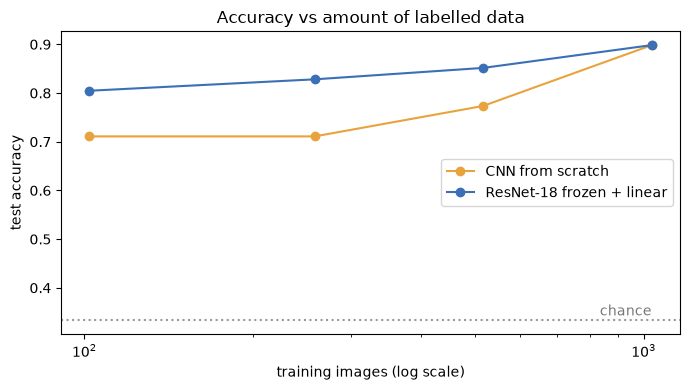

,CNN from scratch,ResNet-18 frozen + linear
102,0.711,0.805
258,0.711,0.828
516,0.773,0.852
1034,0.898,0.898


In [7]:
rng = np.random.default_rng(SEED); ys = split["train"][1]
curve = {}
for frac in [0.1, 0.25, 0.5, 1.0]:
    idx = np.sort(np.concatenate([rng.permutation(np.where(ys == c)[0])[:max(3, int(frac * (ys == c).sum()))] for c in range(3)]))
    m, _ = train_scratch(idx)
    curve[len(idx)] = {"CNN from scratch": accuracy(y_test, evaluate(m, tl)[1]),
                       "ResNet-18 frozen + linear": accuracy(y_test, linear_probe(feats["ResNet-18"], idx=torch.tensor(idx))[0]("test"))}
curve = pd.DataFrame(curve).T
fig, ax = plt.subplots(figsize=(7, 4))
for c, col in zip(curve.columns, ["#e8a33d", "#3b6fb6"]): ax.plot(curve.index, curve[c], "o-", color=col, label=c)
ax.axhline(1 / 3, ls=":", color="#999"); ax.text(curve.index[-1], 1 / 3 + .01, "chance", ha="right", color="#777")
ax.set(xscale="log", xlabel="training images (log scale)", ylabel="test accuracy", title="Accuracy vs amount of labelled data"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "p4_data_efficiency.png", dpi=110); plt.show()
curve.round(3)

## 6. Где ошибается лучшая модель

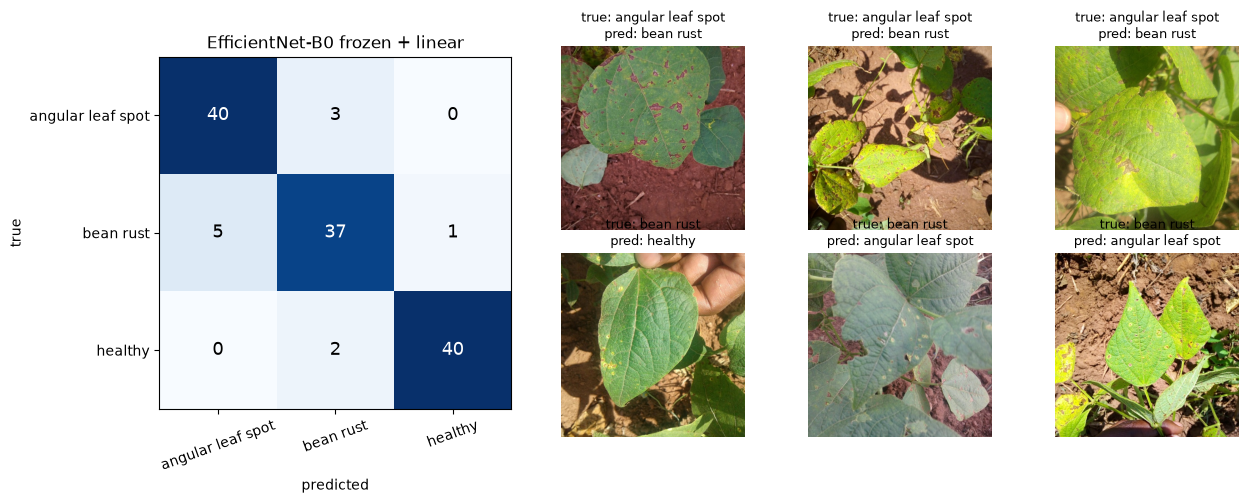

In [8]:
best = max(preds, key=lambda k: accuracy(y_test, preds[k])); p = preds[best]
cm = confusion(y_test, p, 3)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.6]})
ax[0].imshow(cm, cmap="Blues")
for i in range(3):
    for j in range(3): ax[0].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)
ax[0].set_xticks(range(3), CLASSES, rotation=20); ax[0].set_yticks(range(3), CLASSES); ax[0].set(xlabel="predicted", ylabel="true", title=best)
wrong = np.where(p != y_test)[0][:6]; ax[1].axis("off")
for k, i in enumerate(wrong):
    a = fig.add_axes([0.42 + (k % 3) * 0.19, 0.5 - (k // 3) * 0.45, 0.17, 0.4]); a.imshow(split["test"][0][i]); a.axis("off")
    a.set_title(f"true: {CLASSES[y_test[i]]}\npred: {CLASSES[p[i]]}", fontsize=9)
plt.savefig(FIG / "p4_errors.png", dpi=110, bbox_inches="tight"); plt.show()

In [9]:
json.dump({"test": {k: {"accuracy": accuracy(y_test, v), "macro_f1": macro_f1(y_test, v, 3)} for k, v in preds.items()},
           "data_efficiency": curve.to_dict(), "scratch_seconds": t_cnn}, open(RES / "p4_summary.json", "w"), indent=1)

## 7. Выводы

1. **На всех 1 034 изображениях замороженные признаки ImageNet не уступают CNN, обученной с нуля.** ResNet-18 + линейный
   слой даёт 89,8 % точности на test, столько же, сколько CNN с нуля (89,8 %), при этом обучаются 1 539 весов вместо
   1,17 млн, и обучение занимает секунды вместо 3,3 минуты. Признаки EfficientNet-B0 ещё лучше: 91,4 %.
2. **Чем меньше разметки, тем больше выигрыш transfer learning.** На 102 изображениях замороженная ResNet-18 даёт 80,5 %
   против 71,1 % у CNN с нуля, на 258 — 82,8 % против 71,1 %, на 516 — 85,2 % против 77,3 %. Только на полном train сеть с
   нуля догоняет.
3. **Знания из ImageNet переносятся на болезни растений.** Ни на одном из 1,3 млн фото ImageNet нет болезней фасоли, но
   выученные там края, текстуры и цветовые пятна отделяют пустулы ржавчины от пятнистости.
4. **Ошибки** — в основном между двумя болезнями (обе — бурые пятна); здоровые листья путаются редко.
5. При 128 изображениях в test 95 %-интервалы около ±5 пунктов, поэтому 89,8 % против 91,4 % — не решающая разница;
   однозначный результат — кривая эффективности по данным. Практика 5 проверяет, помогает ли дальше обновлять веса сети.